# Outcome predictor 

Take in specific game states and predict the outcome x = specific game states, y = yards gained, turnover, touch down, etc <br>
Goal: P(outcome | game state, offensive personnel, defensive personnel) 

## EDA 
- Offensive & Defensive Personnel have 500+ unique combinations, could be something to use later but for now not worth it. 
- when def pass rushers is NAN it's almost always a run play. (only 2 pass)
- In our regression problem 3rd downs and longer distances are inherently more noisy 

In [1]:
import numpy as np
import pandas as pd
import re
import time 
import matplotlib.pyplot as plt

import nflreadpy as nfl

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


# Gradient Boosting 
from lightgbm import LGBMClassifier
from lightgbm import LGBMRegressor

# Metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    brier_score_loss
)
from sklearn.calibration import CalibrationDisplay




In [2]:
pd.set_option('display.max_columns', None)
seasons = list(range(2021, 2026))

pbp_rows = ['play_id', 'game_id', 'down', 'ydstogo', 'first_down', 'play_type_nfl', 'touchdown', 'yardline_100', 'yards_gained', 'qtr', 'quarter_seconds_remaining', 'goal_to_go', 'score_differential', 'shotgun', 'no_huddle', 'fumble_lost', 'interception', 'season']
participation_rows = ['play_id', 'nflverse_game_id', 'offense_formation', 'offense_personnel', 'defenders_in_box', 'defense_personnel', 'defense_man_zone_type', 'defense_coverage_type', 'number_of_pass_rushers']

pbp = nfl.load_pbp(seasons).to_pandas()
pbp_columns = pbp.columns.tolist()
pbp = pbp[pbp_rows]
print(pbp.shape)

# Participation dataframe
participation = nfl.load_participation(seasons).to_pandas()
participation_columns = participation.columns.tolist()
participation = participation[participation_rows]
print(participation.shape)

working_df = pd.merge(
    pbp,
    participation,
    left_on=['game_id', 'play_id'],
    right_on=['nflverse_game_id', 'play_id'],
    how='inner'
)

print(working_df.shape)

(247284, 18)
(238135, 9)
(236627, 26)


In [3]:
# print col names
print(pbp_columns)
print(participation_columns)
working_df['play_type_nfl'].value_counts()

['play_id', 'game_id', 'old_game_id', 'home_team', 'away_team', 'season_type', 'week', 'posteam', 'posteam_type', 'defteam', 'side_of_field', 'yardline_100', 'game_date', 'quarter_seconds_remaining', 'half_seconds_remaining', 'game_seconds_remaining', 'game_half', 'quarter_end', 'drive', 'sp', 'qtr', 'down', 'goal_to_go', 'time', 'yrdln', 'ydstogo', 'ydsnet', 'desc', 'play_type', 'yards_gained', 'shotgun', 'no_huddle', 'qb_dropback', 'qb_kneel', 'qb_spike', 'qb_scramble', 'pass_length', 'pass_location', 'air_yards', 'yards_after_catch', 'run_location', 'run_gap', 'field_goal_result', 'kick_distance', 'extra_point_result', 'two_point_conv_result', 'home_timeouts_remaining', 'away_timeouts_remaining', 'timeout', 'timeout_team', 'td_team', 'td_player_name', 'td_player_id', 'posteam_timeouts_remaining', 'defteam_timeouts_remaining', 'total_home_score', 'total_away_score', 'posteam_score', 'defteam_score', 'score_differential', 'posteam_score_post', 'defteam_score_post', 'score_differential

play_type_nfl
PASS                            92543
RUSH                            76533
KICK_OFF                        14472
PENALTY                         12215
PUNT                            10990
SACK                             6874
XP_KICK                          6462
FIELD_GOAL                       5594
TIMEOUT                          4276
INTERCEPTION                     2211
END_QUARTER                      1750
UNSPECIFIED                       813
PAT2                              682
GAME_START                        569
END_GAME                          569
FUMBLE_RECOVERED_BY_OPPONENT       67
COMMENT                             4
FREE_KICK                           3
Name: count, dtype: int64

# Preprocessing 

In [ ]:
wanted_plays = ['PASS', 'RUSH', 'INTERCEPTION', 'SACK']
working_df = working_df[working_df['play_type_nfl'].isin(wanted_plays)]
working_df.loc[
    (working_df['play_type_nfl'] == 'INTERCEPTION') |  (working_df['play_type_nfl'] == 'SACK'),
    'play_type_nfl'
] = 'PASS'
working_df['turnover'] = (working_df['fumble_lost'].astype(int) | working_df['interception'].astype(int)) # create turnover feature 
working_df.head()
# print(working_df.shape)
categorical_cols_unknown = [
    'defense_man_zone_type',
    'defense_coverage_type',
]

working_df[categorical_cols_unknown] = working_df[categorical_cols_unknown].fillna('UNKNOWN')
working_df['number_of_pass_rushers'] = working_df['number_of_pass_rushers'].fillna(-1)
working_df['offense_formation'] = (
    working_df['offense_formation'].fillna('UNKNOWN')
)
working_df.isna().mean() * 100

play_id                      0.000000
game_id                      0.000000
down                         0.000000
ydstogo                      0.000000
first_down                   0.000000
play_type_nfl                0.000000
touchdown                    0.000000
yardline_100                 0.000000
yards_gained                 0.000000
qtr                          0.000000
quarter_seconds_remaining    0.000000
goal_to_go                   0.000000
score_differential           0.000000
shotgun                      0.000000
no_huddle                    0.000000
fumble_lost                  0.000000
interception                 0.000000
season                       0.000000
nflverse_game_id             0.000000
offense_formation            0.000000
offense_personnel            0.000000
defenders_in_box             0.002245
defense_personnel            0.000000
defense_man_zone_type        0.000000
defense_coverage_type        0.000000
number_of_pass_rushers       0.000000
turnover    

In [5]:
def parse_personnel(personnel, position_groups):
    """Convert personnel strings into counts for standardized position groups."""
    counts = {group: 0 for group in position_groups}

    if pd.isna(personnel):
        return pd.Series(counts)

    # Extract pairs such as ('4', 'DL'), ('3', 'CB')
    entries = re.findall(r'(\d+)\s*([A-Z]+)', personnel.upper())

    for count, position in entries:
        count = int(count)

        # Map each position to its standardized group
        for group, positions in position_groups.items():
            if position in positions:
                counts[group] += count
                break

    return pd.Series(counts)


# Defensive personnel: DL, LB, DB
defense_groups = {
    'def_DL': {'DL', 'DE', 'DT', 'NT'},
    'def_LB': {'LB', 'ILB', 'OLB', 'MLB'},
    'def_DB': {'DB', 'CB', 'FS', 'SS', 'S'}
}

# Offensive personnel: RB, TE, WR
offense_groups = {
    'off_RB': {'RB', 'HB', 'FB', 'TB'},
    'off_TE': {'TE'},
    'off_WR': {'WR'}
}

# Generate standardized numerical features
defense_counts = working_df['defense_personnel'].apply(
    parse_personnel, position_groups=defense_groups
).add_prefix('')

offense_counts = working_df['offense_personnel'].apply(
    parse_personnel, position_groups=offense_groups
).add_prefix('')

# Add features to the original dataframe
working_df = pd.concat(
    [working_df, defense_counts, offense_counts],
    axis=1
)

# Inspect the results
display(working_df[
    ['defense_personnel', 'def_DL', 'def_LB', 'def_DB',
     'offense_personnel', 'off_RB', 'off_TE', 'off_WR']
].head(20))

,defense_personnel,def_DL,def_LB,def_DB,offense_personnel,off_RB,off_TE,off_WR
2,"3 DL, 4 LB, 4 DB",3,4,4,"1 RB, 2 TE, 2 WR",1,2,2
3,"3 DL, 4 LB, 4 DB",3,4,4,"1 RB, 2 TE, 2 WR",1,2,2
4,"2 DL, 4 LB, 5 DB",2,4,5,"1 RB, 1 TE, 3 WR",1,1,3
6,"3 DL, 4 LB, 4 DB",3,4,4,"1 RB, 2 TE, 2 WR",1,2,2
7,"3 DL, 4 LB, 4 DB",3,4,4,"1 RB, 2 TE, 2 WR",1,2,2
8,"3 DL, 4 LB, 4 DB",3,4,4,"1 RB, 2 TE, 2 WR",1,2,2
9,"2 DL, 4 LB, 5 DB",2,4,5,"1 RB, 1 TE, 3 WR",1,1,3
10,"2 DL, 4 LB, 5 DB",2,4,5,"1 RB, 1 TE, 3 WR",1,1,3
14,"2 DL, 4 LB, 5 DB",2,4,5,"1 RB, 1 TE, 3 WR",1,1,3
15,"2 DL, 3 LB, 6 DB",2,3,6,"1 RB, 0 TE, 4 WR",1,0,4


In [6]:
display(working_df.head())

,play_id,game_id,down,ydstogo,first_down,play_type_nfl,touchdown,yardline_100,yards_gained,qtr,quarter_seconds_remaining,goal_to_go,score_differential,shotgun,no_huddle,fumble_lost,interception,season,nflverse_game_id,offense_formation,offense_personnel,defenders_in_box,defense_personnel,defense_man_zone_type,defense_coverage_type,number_of_pass_rushers,turnover,def_DL,def_LB,def_DB,off_RB,off_TE,off_WR
2,55.0,2021_01_ARI_TEN,1.0,10.0,0.0,RUSH,0.0,75.0,-3.0,1.0,900.0,0.0,0.0,0.0,0.0,0.0,0.0,2021,2021_01_ARI_TEN,SINGLEBACK,"1 RB, 2 TE, 2 WR",7.0,"3 DL, 4 LB, 4 DB",UNKNOWN,UNKNOWN,-1.0,0,3,4,4,1,2,2
3,76.0,2021_01_ARI_TEN,2.0,13.0,0.0,PASS,0.0,78.0,3.0,1.0,863.0,0.0,0.0,1.0,0.0,0.0,0.0,2021,2021_01_ARI_TEN,SHOTGUN,"1 RB, 2 TE, 2 WR",7.0,"3 DL, 4 LB, 4 DB",ZONE_COVERAGE,COVER_6,4.0,0,3,4,4,1,2,2
4,100.0,2021_01_ARI_TEN,3.0,10.0,0.0,PASS,0.0,75.0,0.0,1.0,822.0,0.0,0.0,1.0,0.0,0.0,0.0,2021,2021_01_ARI_TEN,SHOTGUN,"1 RB, 1 TE, 3 WR",5.0,"2 DL, 4 LB, 5 DB",ZONE_COVERAGE,COVER_6,4.0,0,2,4,5,1,1,3
6,152.0,2021_01_ARI_TEN,1.0,10.0,1.0,PASS,0.0,61.0,38.0,1.0,807.0,0.0,0.0,1.0,0.0,0.0,0.0,2021,2021_01_ARI_TEN,SHOTGUN,"1 RB, 2 TE, 2 WR",8.0,"3 DL, 4 LB, 4 DB",ZONE_COVERAGE,COVER_3,4.0,0,3,4,4,1,2,2
7,181.0,2021_01_ARI_TEN,1.0,10.0,0.0,RUSH,0.0,23.0,2.0,1.0,775.0,0.0,0.0,1.0,1.0,0.0,0.0,2021,2021_01_ARI_TEN,SHOTGUN,"1 RB, 2 TE, 2 WR",6.0,"3 DL, 4 LB, 4 DB",UNKNOWN,UNKNOWN,-1.0,0,3,4,4,1,2,2


In [7]:
# Groups 
game_state = ['down', 'ydstogo', 'yardline_100', 'qtr', 'quarter_seconds_remaining', 'goal_to_go', 'score_differential']
offensive_state = ['play_type_nfl', 'shotgun', 'no_huddle', 'offense_formation', 'off_RB', 'off_TE', 'off_WR']
defensive_state = ['defenders_in_box', 'def_DL', 'def_LB', 'def_DB', 'defense_man_zone_type', 'defense_coverage_type', 'number_of_pass_rushers']
X_features = game_state + offensive_state + defensive_state
targets = ['first_down', 'touchdown', 'yards_gained', 'turnover']


In [8]:
# Create train test val temporal split 
train_df = working_df[working_df['season'] <= 2023]
val_df = working_df[working_df['season'] == 2024]
test_df = working_df[working_df['season'] == 2025]

X_train = train_df[X_features]
y_train = train_df[targets]

X_val_pre = val_df[X_features]
y_val = val_df[targets]

X_test = test_df[X_features]
y_test = test_df[targets]

print(f"{X_train.size}, X_val: {X_val_pre.size}, X_test: {X_test.size}")

2263401, X_val: 742854, X_test: 735126


In [ ]:
# Preprocessing Pipeline
# Get numerical and categorical features
numerical_features = X_train.select_dtypes(include=np.number).columns
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scalar', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val_pre)
X_test = preprocessor.transform(X_test)


/var/folders/x1/krxnjmfx1x7frt_xxc_hj88r0000gn/T/ipykernel_80641/3746350631.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=['object', 'category']).columns


# Modeling 

Comparing GB, RF, and Regression models 

1 Input feature row --> results in 4 targets
- yards gained (regression) 5.4 yards 
- touchdown (binary classification) (requires probability) 4% chance touch down
- turnover (binary classification) (requires probability) 2% chance turnover 
- first down (binary classification) (requires probability) 40% chance first down

Strategies for implementing these 4 targets
- One ML model for each target (try GB, RF and Regression models for each and record results) 
- One classification model with different heads for each target (shared weights) (interesting concept)

In [10]:
# GB Target Yards
y_yards_train = y_train['yards_gained']
yards_model = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.05,
    random_state=42
)

yards_model.fit(X_train, y_yards_train)
yards_predictions = yards_model.predict(X_val)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004790 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 633
[LightGBM] [Info] Number of data points in the train set: 107781, number of used features: 44
[LightGBM] [Info] Start training from score 5.367375


In [11]:
# GB Target touchdown
y_touchdown_train = y_train['touchdown']
touchdown_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    random_state=42
)

touchdown_model.fit(X_train, y_touchdown_train)
td_predictions = touchdown_model.predict(X_val)

[LightGBM] [Info] Number of positive: 4206, number of negative: 103575
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004805 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 633
[LightGBM] [Info] Number of data points in the train set: 107781, number of used features: 44
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.039024 -> initscore=-3.203784
[LightGBM] [Info] Start training from score -3.203784


In [12]:
# GB Target turnover
y_turnover_train = y_train['turnover']
turnover_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    random_state=42
)

turnover_model.fit(X_train, y_turnover_train)
turnover_predictions = turnover_model.predict(X_val)

[LightGBM] [Info] Number of positive: 2112, number of negative: 105669
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003182 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 633
[LightGBM] [Info] Number of data points in the train set: 107781, number of used features: 44
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.019595 -> initscore=-3.912676
[LightGBM] [Info] Start training from score -3.912676


In [13]:
# GB Target FD
y_fd_train = y_train['first_down']
fd_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    random_state=42
)

fd_model.fit(X_train, y_fd_train)
fd_predictions = fd_model.predict(X_val)

[LightGBM] [Info] Number of positive: 31352, number of negative: 76429
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003144 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 633
[LightGBM] [Info] Number of data points in the train set: 107781, number of used features: 44
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.290886 -> initscore=-0.891084
[LightGBM] [Info] Start training from score -0.891084


In [ ]:
# Establishing a baseline to put our regression model against
baseline = np.full(len(y_val['yards_gained']), y_yards_train.mean()) # predicting training set mean for every one

for name, yards_preds in [
    ("Baseline", baseline),
    ("Regressor", yards_predictions),
]:
    print(f'\nName: {name}')
    print(f'MAE:', mean_absolute_error(y_val['yards_gained'], yards_preds))
    print(f'MSE:', mean_squared_error(y_val['yards_gained'], yards_preds))
    print(f'r2:', r2_score(y_val['yards_gained'], yards_preds))


Name: Baseline
MAE: 5.7558773685846765
MSE: 73.47315948795563
r2: -7.070347763327156e-05

Name: Regressor
MAE: 5.536266265070528
MSE: 70.29277190213486
r2: 0.04321874361365052


In [ ]:
td_baseline = np.zeros(len(y_val['touchdown']))
turnover_baseline = np.zeros(len(y_val['turnover']))
fd_baseline = np.zeros(len(y_val['first_down']))

for name, yards_preds in [
    ("TD_Baseline", td_baseline),
    ("TD_model", td_predictions),
    ("turnover_Baseline", turnover_baseline),
    ("Turnover_model", turnover_predictions),
    ("fd_baseline", fd_baseline),
    ("FD_model", fd_predictions)
]:
    print(f'\nName: {name}')
    print(f'Accuracy:', accuracy_score(y_val['touchdown'], yards_preds))
    print(f'Precision:', precision_score(y_val['touchdown'], yards_preds))
    print(f'Recall:', recall_score(y_val['touchdown'], yards_preds))
    print(f'F1:', f1_score(y_val['touchdown'], yards_preds))


Name: TD_Baseline
Accuracy: 0.9592638661163566
Precision: 0.0
Recall: 0.0
F1: 0.0

Name: TD_model
Accuracy: 0.9605925255837621
Precision: 0.5588972431077694
Recall: 0.15475364330326163
F1: 0.24239130434782608

Name: turnover_Baseline
Accuracy: 0.9592638661163566
Precision: 0.0
Recall: 0.0
F1: 0.0

Name: Turnover_model
Accuracy: 0.9591790580652456
Precision: 0.0
Recall: 0.0
F1: 0.0

Name: fd_baseline
Accuracy: 0.9592638661163566
Precision: 0.0
Recall: 0.0
F1: 0.0

Name: FD_model
Accuracy: 0.8414937524735682
Precision: 0.06855840927920465
Recall: 0.22970159611380986
F1: 0.10559897910352528


/Users/topgjulian/Desktop/Projects/ML/Shot-Caller/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/topgjulian/Desktop/Projects/ML/Shot-Caller/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/topgjulian/Desktop/Projects/ML/Shot-Caller/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _

In [16]:
results = X_val_pre[["play_type_nfl"]].copy()

results["actual"] = y_val["yards_gained"]
results["predicted"] = yards_predictions
results["absolute_error"] = (
    results["actual"] - results["predicted"]
).abs()

print(
    results.groupby("play_type_nfl")
    .agg(
        plays=("actual", "size"),
        actual_mean=("actual", "mean"),
        predicted_mean=("predicted", "mean"),
        MAE=("absolute_error", "mean")
    )
)

               plays  actual_mean  predicted_mean       MAE
play_type_nfl                                              
PASS           19946     6.205505        6.512085  7.010198
RUSH           15428     4.449054        4.307007  3.630702


In [17]:
# Yards to go and down evaluation 
results = X_val_pre[['down', 'ydstogo']]
results["actual"] = y_val['yards_gained']
results["predicted"] = yards_predictions
results["absolute_error"] = (
    results["actual"] - results["predicted"]
).abs()

print(
    results.groupby("down")
    .agg(
        plays=("actual", "size"),
        actual_mean=("actual", "mean"),
        predicted_mean=("predicted", "mean"),
        MAE=("absolute_error", "mean")
    )
)
print(
    results.groupby("ydstogo")
    .agg(
        plays=("actual", "size"),
        actual_mean=("actual", "mean"),
        predicted_mean=("predicted", "mean"),
        MAE=("absolute_error", "mean")
    )
)


      plays  actual_mean  predicted_mean       MAE
down                                              
1.0   15641     5.501630        5.441054  5.203502
2.0   11739     5.458898        5.569729  5.406090
3.0    7204     5.349389        5.845050  6.474983
4.0     790     4.740506        4.739535  5.498785
         plays  actual_mean  predicted_mean        MAE
ydstogo                                               
1.0       1993     3.348721        3.685147   3.452252
2.0       1424     4.267556        4.652005   4.479262
3.0       1486     4.588156        4.888955   5.069510
4.0       1511     5.023825        5.250318   5.383129
5.0       1794     5.370680        5.422087   5.757242
6.0       1703     5.425719        5.601874   5.950842
7.0       1695     5.361062        5.694269   5.894612
8.0       1547     5.716871        5.869356   6.422181
9.0       1383     5.630513        5.861944   6.096266
10.0     16873     5.746814        5.717517   5.546093
11.0       731     5.502052       

# TD Model Deep Evaluation

## Evaluation Pipeline
- Does the model produce a useful signal (better results than naive baseline)
- Does the output have useful information (evaluate the probabilities)
- Is the model sensible (Is it using the correct features)
- Decision usefulness (thresholds + test set)

### Status
- Passed evaluation

In [ ]:
td_baseline = np.zeros(len(y_val['touchdown']))

for name, yards_preds in [
    ("TD_Baseline", td_baseline),
    ("TD_model", td_predictions),
]:
    print(f'\nName: {name}')
    print(f'Accuracy:', accuracy_score(y_val['touchdown'], yards_preds))
    print(f'Precision:', precision_score(y_val['touchdown'], yards_preds))
    print(f'Recall:', recall_score(y_val['touchdown'], yards_preds))
    print(f'F1:', f1_score(y_val['touchdown'], yards_preds))


Name: TD_Baseline
Accuracy: 0.9592638661163566
Precision: 0.0
Recall: 0.0
F1: 0.0

Name: TD_model
Accuracy: 0.9605925255837621
Precision: 0.5588972431077694
Recall: 0.15475364330326163
F1: 0.24239130434782608


/Users/topgjulian/Desktop/Projects/ML/Shot-Caller/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


[[33757   176]
 [ 1218   223]]


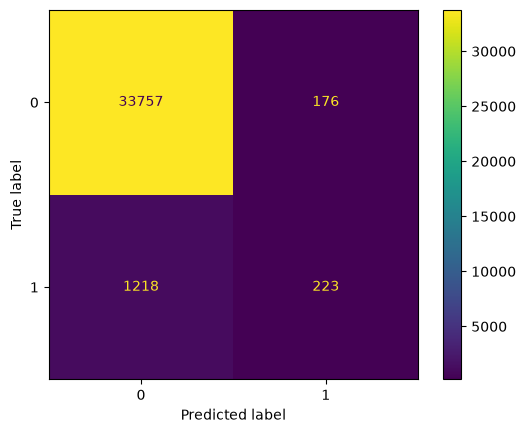

In [19]:
cm = confusion_matrix(
    y_val["touchdown"],
    td_predictions
)

print(cm)

ConfusionMatrixDisplay(cm).plot()
plt.show()

In [20]:

# Checking models probability output usefulness 
td_probabilities = touchdown_model.predict_proba(X_val)[:, 1]

td_eval = pd.DataFrame({
    'td_probability': td_probabilities,
    'actual_td': y_val['touchdown']
})

bin_edges = [0, 0.05, 0.10, 0.20, 0.40, 1.0]

td_eval['probability_bin'] = pd.cut(
    td_eval['td_probability'],
    bins=bin_edges,
    include_lowest=True
)
display(td_eval)

td_calibration = (
    td_eval
    .groupby('probability_bin', observed=False)
    .agg(
        predicted_probability=('td_probability', 'mean'),
        actual_td_rate=('actual_td', 'mean'),
        plays=('actual_td', 'size')
    )
    .reset_index()
)

print(td_calibration)

,td_probability,actual_td,probability_bin
145525,0.002387,0.0,"(-0.001, 0.05]"
145526,0.007412,0.0,"(-0.001, 0.05]"
145527,0.016061,0.0,"(-0.001, 0.05]"
145528,0.008713,0.0,"(-0.001, 0.05]"
145529,0.008852,0.0,"(-0.001, 0.05]"
...,...,...,...
191436,0.015295,0.0,"(-0.001, 0.05]"
191437,0.013109,1.0,"(-0.001, 0.05]"
191440,0.001930,0.0,"(-0.001, 0.05]"
191441,0.001786,0.0,"(-0.001, 0.05]"


  probability_bin  predicted_probability  actual_td_rate  plays
0  (-0.001, 0.05]               0.010735        0.010864  29546
1     (0.05, 0.1]               0.072652        0.056039   2070
2      (0.1, 0.2]               0.138661        0.140997   1766
3      (0.2, 0.4]               0.290853        0.308068   1227
4      (0.4, 1.0]               0.497972        0.492810    765


In [21]:
# Feature importance
feature_importance = touchdown_model.feature_importances_
feature_names = preprocessor.get_feature_names_out()

for feature, score in zip(feature_names, feature_importance):
    print(f"Feature: {feature} | Score: {score}")

Feature: num__down | Score: 93
Feature: num__ydstogo | Score: 155
Feature: num__yardline_100 | Score: 602
Feature: num__qtr | Score: 107
Feature: num__quarter_seconds_remaining | Score: 485
Feature: num__goal_to_go | Score: 4
Feature: num__score_differential | Score: 329
Feature: num__shotgun | Score: 10
Feature: num__no_huddle | Score: 24
Feature: num__off_RB | Score: 37
Feature: num__off_TE | Score: 30
Feature: num__off_WR | Score: 36
Feature: num__defenders_in_box | Score: 107
Feature: num__def_DL | Score: 72
Feature: num__def_LB | Score: 90
Feature: num__def_DB | Score: 48
Feature: num__number_of_pass_rushers | Score: 149
Feature: cat__play_type_nfl_PASS | Score: 101
Feature: cat__play_type_nfl_RUSH | Score: 10
Feature: cat__offense_formation_EMPTY | Score: 20
Feature: cat__offense_formation_I_FORM | Score: 1
Feature: cat__offense_formation_JUMBO | Score: 25
Feature: cat__offense_formation_PISTOL | Score: 21
Feature: cat__offense_formation_SHOTGUN | Score: 21
Feature: cat__offense_

In [ ]:
# Touchdown Threshold Analysis
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

rows = []
for threshold in thresholds:
    yards_preds = (td_probabilities >= threshold).astype(int)
    rows.append({
        'threshold': threshold,
        'accuracy': accuracy_score(y_val['touchdown'], yards_preds),     
        'precision': precision_score(y_val['touchdown'], yards_preds),
        'recall': recall_score(y_val['touchdown'], yards_preds),
        'F1': f1_score(y_val['touchdown'], yards_preds),
    })

threshold_table = pd.DataFrame(rows)
display(threshold_table)


/Users/topgjulian/Desktop/Projects/ML/Shot-Caller/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/topgjulian/Desktop/Projects/ML/Shot-Caller/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,threshold,accuracy,precision,recall,F1
0,0.1,0.909793,0.267163,0.696738,0.386228
1,0.2,0.945638,0.379016,0.523942,0.439849
2,0.3,0.955363,0.443719,0.377516,0.407949
3,0.4,0.958953,0.492810,0.261624,0.341795
4,0.5,0.960593,0.558897,0.154754,0.242391
5,0.6,0.959292,1.000000,0.000694,0.001387
6,0.7,0.959264,0.000000,0.000000,0.000000
7,0.8,0.959264,0.000000,0.000000,0.000000


# FD Model Evaluation

### Status
- Well calibrated (Pass)


Name: fd_Baseline
Accuracy: 0.9592638661163566
Precision: 0.0
Recall: 0.0
F1: 0.0

Name: fd_model
Accuracy: 0.8414937524735682
Precision: 0.06855840927920465
Recall: 0.22970159611380986
F1: 0.10559897910352528
[[33757   176]
 [ 1218   223]]


/Users/topgjulian/Desktop/Projects/ML/Shot-Caller/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


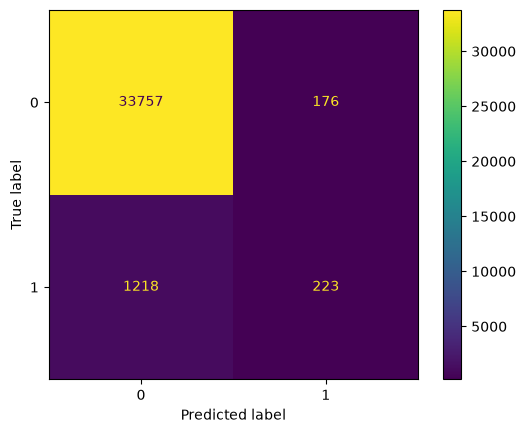

In [ ]:
fd_baseline = np.zeros(len(y_val['first_down']))

for name, yards_preds in [
    ("fd_Baseline", fd_baseline),
    ("fd_model", fd_predictions),
]:
    print(f'\nName: {name}')
    print(f'Accuracy:', accuracy_score(y_val['touchdown'], yards_preds))
    print(f'Precision:', precision_score(y_val['touchdown'], yards_preds))
    print(f'Recall:', recall_score(y_val['touchdown'], yards_preds))
    print(f'F1:', f1_score(y_val['touchdown'], yards_preds))

cm = confusion_matrix(
    y_val["touchdown"],
    td_predictions
)

print(cm)
ConfusionMatrixDisplay(cm).plot()

  probability_bin  predicted_probability  actual_fd_rate  plays
0  (-0.001, 0.05]               0.018386        0.010296    777
1     (0.05, 0.1]               0.077608        0.071887   1558
2      (0.1, 0.2]               0.129434        0.134247   9706
3      (0.2, 0.4]               0.293249        0.294455  14824
4      (0.4, 1.0]               0.546558        0.544482   8509
0.1775998745328514


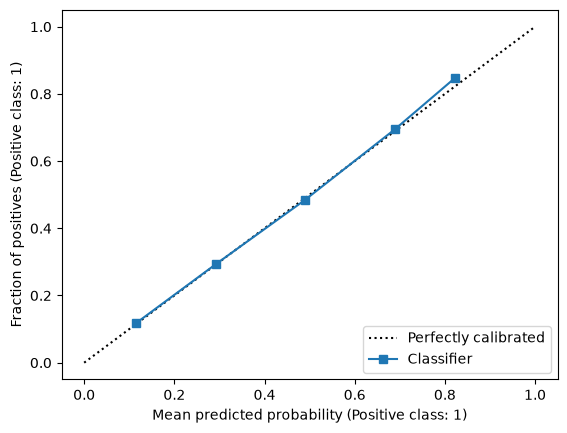

In [30]:
# Checking models probability output usefulness 
fd_probabilities = fd_model.predict_proba(X_val)[:, 1]

fd_eval = pd.DataFrame({
    'fd_probability': fd_probabilities,
    'actual_fd': y_val['first_down']
})

bin_edges = [0, 0.05, 0.10, 0.20, 0.40, 1.0]

fd_eval['probability_bin'] = pd.cut(
    fd_eval['fd_probability'],
    bins=bin_edges,
    include_lowest=True
)

fd_calibration = (
    fd_eval
    .groupby('probability_bin', observed=False)
    .agg(
        predicted_probability=('fd_probability', 'mean'),
        actual_fd_rate=('actual_fd', 'mean'),
        plays=('actual_fd', 'size')
    )
    .reset_index()
)

print(fd_calibration)

score = brier_score_loss(y_val['first_down'], fd_probabilities)
print(score)

# Generates a reliability diagram grouping probabilities into discrete bins
CalibrationDisplay.from_predictions(y_val['first_down'], fd_probabilities, n_bins=5)
plt.show()


In [31]:
# Feature Importance
feature_importances = fd_model.feature_importances_
feature_names = preprocessor.get_feature_names_out()

for name, score in zip(feature_names, feature_importance):
    print(f"Feature: {name} | Score: {score}")

Feature: num__down | Score: 93
Feature: num__ydstogo | Score: 155
Feature: num__yardline_100 | Score: 602
Feature: num__qtr | Score: 107
Feature: num__quarter_seconds_remaining | Score: 485
Feature: num__goal_to_go | Score: 4
Feature: num__score_differential | Score: 329
Feature: num__shotgun | Score: 10
Feature: num__no_huddle | Score: 24
Feature: num__off_RB | Score: 37
Feature: num__off_TE | Score: 30
Feature: num__off_WR | Score: 36
Feature: num__defenders_in_box | Score: 107
Feature: num__def_DL | Score: 72
Feature: num__def_LB | Score: 90
Feature: num__def_DB | Score: 48
Feature: num__number_of_pass_rushers | Score: 149
Feature: cat__play_type_nfl_PASS | Score: 101
Feature: cat__play_type_nfl_RUSH | Score: 10
Feature: cat__offense_formation_EMPTY | Score: 20
Feature: cat__offense_formation_I_FORM | Score: 1
Feature: cat__offense_formation_JUMBO | Score: 25
Feature: cat__offense_formation_PISTOL | Score: 21
Feature: cat__offense_formation_SHOTGUN | Score: 21
Feature: cat__offense_

In [ ]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

rows = []
for threshold in thresholds:
    yards_preds = (fd_probabilities >= threshold).astype(int)
    rows.append({
        'threshold': threshold,
        'accuracy': accuracy_score(y_val['first_down'], yards_preds),     
        'precision': precision_score(y_val['first_down'], yards_preds),
        'recall': recall_score(y_val['first_down'], yards_preds),
        'F1': f1_score(y_val['first_down'], yards_preds),
    })

threshold_table = pd.DataFrame(rows)
display(threshold_table)

,threshold,accuracy,precision,recall,F1
0,0.1,0.353819,0.311783,0.988485,0.474045
1,0.2,0.554532,0.385634,0.863449,0.533152
2,0.3,0.674422,0.462118,0.641493,0.537228
3,0.4,0.726805,0.544482,0.444583,0.489488
4,0.5,0.738933,0.622825,0.288552,0.394387
5,0.6,0.732176,0.701919,0.157950,0.257872
6,0.7,0.722649,0.768014,0.083869,0.151224
7,0.8,0.707356,0.848485,0.008061,0.015970


# Turnover Model Evaluation

# Status
- Need's more evidence. 
- Doesn't seem poorly calibrated but is not perfect and could just be guessing 
- Extremely weak signal did not correctly predict one turnover
- Using some good features but some features that are useless for turnover (may require a different feature set then the others)
- The model is actually able to predict a higher probability for turnovers vs non turnover plays (this model is probably useable)


Name: turnover_Baseline
Accuracy: 0.9815401142081756
Precision: 0.0
Recall: 0.0
F1: 0.0

Name: turnover_model
Accuracy: 0.9814553061570646
Precision: 0.0
Recall: 0.0
F1: 0.0
[[34718     3]
 [  653     0]]


/Users/topgjulian/Desktop/Projects/ML/Shot-Caller/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


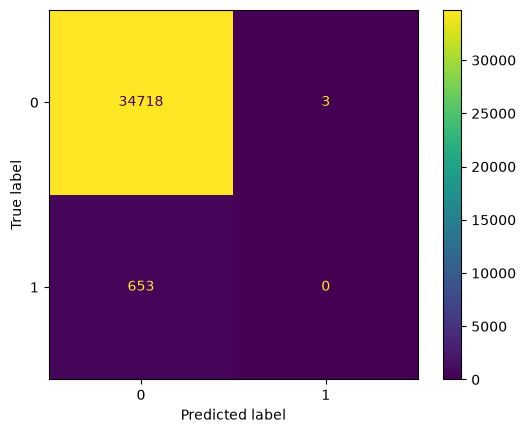

In [ ]:
turnover_baseline = np.zeros(len(y_val['turnover']))

for name, yards_preds in [
    ("turnover_Baseline", turnover_baseline),
    ("turnover_model", turnover_predictions),
]:
    print(f'\nName: {name}')
    print(f'Accuracy:', accuracy_score(y_val['turnover'], yards_preds))
    print(f'Precision:', precision_score(y_val['turnover'], yards_preds))
    print(f'Recall:', recall_score(y_val['turnover'], yards_preds))
    print(f'F1:', f1_score(y_val['turnover'], yards_preds))

cm = confusion_matrix(
    y_val["turnover"],
    turnover_predictions
)

print(cm)
ConfusionMatrixDisplay(cm).plot()

  probability_bin  predicted_probability  actual_turnover_rate  plays
0  (-0.001, 0.05]               0.016936              0.017884  34780
1     (0.05, 0.1]               0.063404              0.049310    507
2      (0.1, 0.2]               0.129104              0.060606     66
3      (0.2, 0.4]               0.271356              0.058824     17
4      (0.4, 1.0]               0.700685              0.250000      4
0.018073544967276128


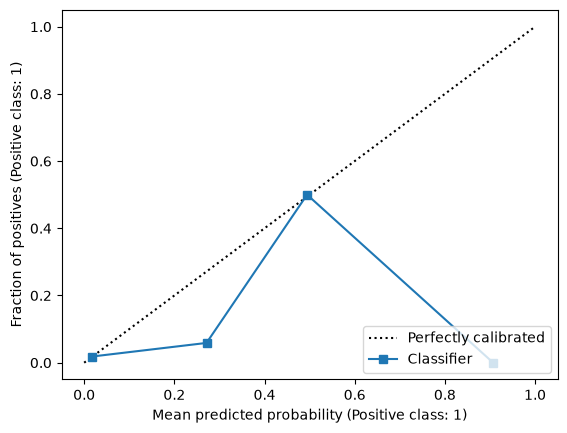

In [34]:
# Checking models probability output usefulness 
turnover_probabilities = turnover_model.predict_proba(X_val)[:, 1]

turnover_eval = pd.DataFrame({
    'turnover_probability': turnover_probabilities,
    'actual_turnovers': y_val['turnover']
})

bin_edges = [0, 0.05, 0.10, 0.20, 0.40, 1.0]

turnover_eval['probability_bin'] = pd.cut(
    turnover_eval['turnover_probability'],
    bins=bin_edges,
    include_lowest=True
)

turnover_calibration = (
    turnover_eval
    .groupby('probability_bin', observed=False)
    .agg(
        predicted_probability=('turnover_probability', 'mean'),
        actual_turnover_rate=('actual_turnovers', 'mean'),
        plays=('actual_turnovers', 'size')
    )
    .reset_index()
)

print(turnover_calibration)

score = brier_score_loss(y_val['turnover'], turnover_probabilities)
print(score)

# Generates a reliability diagram grouping probabilities into discrete bins
CalibrationDisplay.from_predictions(y_val['turnover'], turnover_probabilities, n_bins=5)
plt.show()

In [35]:
# Feature Importance
feature_importances = turnover_model.feature_importances_
feature_names = preprocessor.get_feature_names_out()

for name, score in zip(feature_names, feature_importance):
    print(f"Feature: {name} | Score: {score}")

Feature: num__down | Score: 93
Feature: num__ydstogo | Score: 155
Feature: num__yardline_100 | Score: 602
Feature: num__qtr | Score: 107
Feature: num__quarter_seconds_remaining | Score: 485
Feature: num__goal_to_go | Score: 4
Feature: num__score_differential | Score: 329
Feature: num__shotgun | Score: 10
Feature: num__no_huddle | Score: 24
Feature: num__off_RB | Score: 37
Feature: num__off_TE | Score: 30
Feature: num__off_WR | Score: 36
Feature: num__defenders_in_box | Score: 107
Feature: num__def_DL | Score: 72
Feature: num__def_LB | Score: 90
Feature: num__def_DB | Score: 48
Feature: num__number_of_pass_rushers | Score: 149
Feature: cat__play_type_nfl_PASS | Score: 101
Feature: cat__play_type_nfl_RUSH | Score: 10
Feature: cat__offense_formation_EMPTY | Score: 20
Feature: cat__offense_formation_I_FORM | Score: 1
Feature: cat__offense_formation_JUMBO | Score: 25
Feature: cat__offense_formation_PISTOL | Score: 21
Feature: cat__offense_formation_SHOTGUN | Score: 21
Feature: cat__offense_

In [ ]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

rows = []
for threshold in thresholds:
    yards_preds = (turnover_probabilities >= threshold).astype(int)
    rows.append({
        'threshold': threshold,
        'accuracy': accuracy_score(y_val['turnover'], yards_preds),     
        'precision': precision_score(y_val['turnover'], yards_preds),
        'recall': recall_score(y_val['turnover'], yards_preds),
        'F1': f1_score(y_val['turnover'], yards_preds),
    })

threshold_table = pd.DataFrame(rows)
display(threshold_table)

,threshold,accuracy,precision,recall,F1
0,0.1,0.979420,0.068966,0.009188,0.016216
1,0.2,0.981060,0.095238,0.003063,0.005935
2,0.3,0.981370,0.200000,0.003063,0.006033
3,0.4,0.981484,0.250000,0.001531,0.003044
4,0.5,0.981455,0.000000,0.000000,0.000000
5,0.6,0.981484,0.000000,0.000000,0.000000
6,0.7,0.981484,0.000000,0.000000,0.000000
7,0.8,0.981484,0.000000,0.000000,0.000000


### Deeper Turnover Model Evaluation
- Is it giving good signal

In [48]:
turnover_test_proba = turnover_model.predict_proba(X_test)[:, 1]
df = pd.DataFrame({'prob': turnover_test_proba, 'label': y_test['turnover']})

means_prob = df.groupby('label')['prob'].mean()

display(means_prob)

label
0    0.017751
1    0.027184
Name: prob, dtype: float64

### Global Feature Analysis

,feature,importance
4,num__quarter_seconds_remaining,581
2,num__yardline_100,416
6,num__score_differential,374
1,num__ydstogo,201
3,num__qtr,144
0,num__down,133
12,num__defenders_in_box,131
16,num__number_of_pass_rushers,122
26,cat__offense_formation_UNKNOWN,114
13,num__def_DL,98


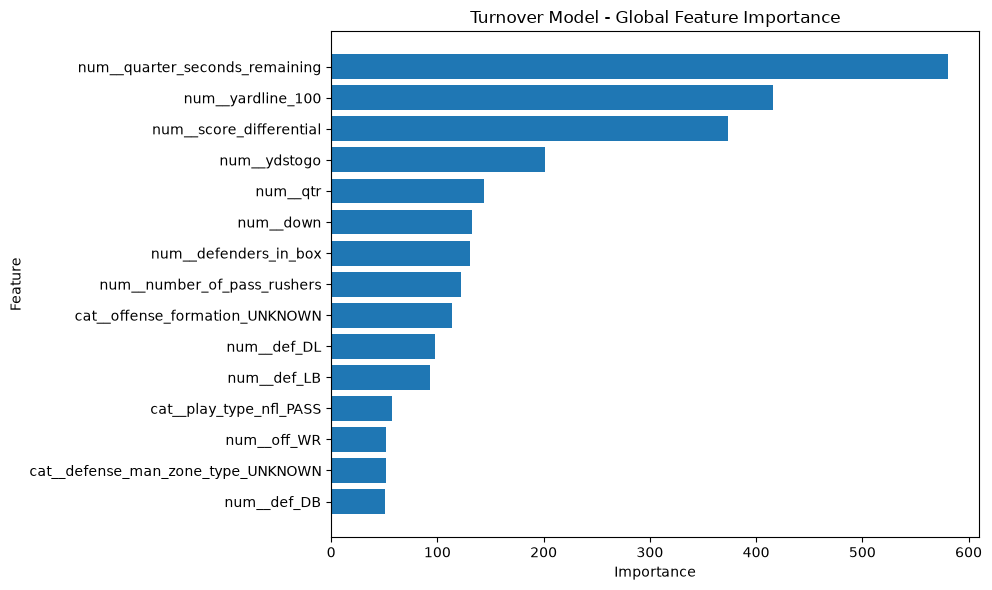

In [49]:
feature_names = preprocessor.get_feature_names_out()
importances = turnover_model.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

display(importance_df.head(20))
top_features = importance_df.head(15).sort_values("importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Turnover Model - Global Feature Importance")
plt.tight_layout()
plt.show()

# Investigating turning the Yards model into a distribution

In [ ]:
# Training multiple LGMBRegressor using Quantile to get the 10th, 25th, 50th, 75th, 90th percentile 

quantiles = [0.1, 0.25, 0.5, 0.75, 0.9]
yards_preds = {}
y_yards_train = y_train['yards_gained']

for q in quantiles:
    yards_model = LGBMRegressor(
        objective='quantile',
        alpha=q,
        n_estimators=100,
        learning_rate=0.05,
        random_state=42
    )
    yards_model.fit(X_train, y_yards_train)
    yards_preds[q] = yards_model.predict(X_val)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004453 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 633
[LightGBM] [Info] Number of data points in the train set: 107781, number of used features: 44
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005381 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 633
[LightGBM] [Info] Number of data points in the train set: 107781, number of used features: 44
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003359 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 633
[LightGBM] [Info] Number of data po

array([ 0.        ,  0.        ,  0.        , ..., -0.99407947,
       -0.99407947, -0.99407947], shape=(35374,))

In [60]:
df = pd.DataFrame({"preds (10)": yards_preds[0.1], "preds (25)": yards_preds[0.25], "preds (50)": yards_preds[0.5], "preds (75)": yards_preds[0.75], "preds (90)": yards_preds[0.9], "label": y_val['yards_gained']})
display(df.head(10))

quantiles = [0.1, 0.25, 0.5, 0.75, 0.9]

quantile_preds = pd.DataFrame({
    "p10": yards_preds[0.1],
    "p25": yards_preds[0.25],
    "p50": yards_preds[0.5],
    "p75": yards_preds[0.75],
    "p90": yards_preds[0.9]
})

ordering_violations = (
    (quantile_preds["p10"] > quantile_preds["p25"]) |
    (quantile_preds["p25"] > quantile_preds["p50"]) |
    (quantile_preds["p50"] > quantile_preds["p75"]) |
    (quantile_preds["p75"] > quantile_preds["p90"])
)

print("Ordering violations:", ordering_violations.sum())
print("Violation rate:", ordering_violations.mean())

,preds (10),preds (25),preds (50),preds (75),preds (90),label
145525,0.000000,0.994079,3.004979,5.951734,10.996725,3.0
145526,0.000000,0.000000,5.024545,12.085599,20.633885,22.0
145527,0.000000,0.000000,5.053626,9.995503,17.681066,9.0
145528,-0.142625,0.889788,2.902713,5.112752,9.721636,2.0
145529,-0.165563,1.000265,3.035420,5.983952,10.593645,2.0
145530,-0.165563,0.994079,3.004979,5.990067,10.996725,2.0
145531,-0.077368,0.000000,2.039004,10.543351,19.248877,8.0
145532,0.000000,0.000000,4.442285,10.589300,17.994385,0.0
145533,-0.115563,1.758247,3.231843,6.580778,10.996725,-3.0
145534,1.983044,3.493954,5.554021,10.440046,15.845781,6.0


Ordering violations: 556
Violation rate: 0.01571775880590264


In [62]:
actual = y_val["yards_gained"].values

for q in quantiles:
    prediction = yards_preds[q]
    observed_rate = (actual <= prediction).mean()

    print(
        f"P{int(q*100)}: "
        f"expected={q:.2f}, "
        f"observed={observed_rate:.3f}"
    )

P10: expected=0.10, observed=0.226
P25: expected=0.25, observed=0.344
P50: expected=0.50, observed=0.509
P75: expected=0.75, observed=0.749
P90: expected=0.90, observed=0.899


In [63]:
p10 = yards_preds[0.1]
p90 = yards_preds[0.9]

coverage_10_90 = ((actual >= p10) & (actual <= p90)).mean()

print("Actual yards inside P10-P90:", coverage_10_90)
print("Expected:", 0.80)

Actual yards inside P10-P90: 0.801633968451405
Expected: 0.8
